In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def get_weather(lat, lon, start, end):
    url = "https://power.larc.nasa.gov/api/temporal/daily/point"
    params = {
        "parameters": "T2M,RH2M,PRECTOTCORR",
        "community": "AG",
        "latitude": lat,
        "longitude": lon,
        "start": start,
        "end": end,
        "format": "JSON",
    }
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    data = r.json()["properties"]["parameter"]
    df = pd.DataFrame(data).rename(columns={
        "T2M": "temp_c", "RH2M": "humidity_pct", "PRECTOTCORR": "rain_mm"})
    df.index = pd.to_datetime(df.index, format="%Y%m%d")
    df = df.replace(-999, np.nan)
    return df

print("Function ready")

Function ready


In [2]:
weather = get_weather(33.68, 73.05, "20231101", "20240430")
print(weather.shape)
weather.head()

(182, 3)


,temp_c,humidity_pct,rain_mm
2023-11-01,20.41,72.57,0.26
2023-11-02,20.32,69.36,1.43
2023-11-03,19.55,62.65,0.00
2023-11-04,19.41,58.51,0.00
2023-11-05,19.21,56.62,0.00


           temp_c  humidity_pct     rain_mm
count  182.000000    182.000000  182.000000
mean    15.537527     56.084341    2.331374
std      4.118038     10.336518    7.109094
min      7.710000     35.990000    0.000000
25%     12.147500     49.472500    0.000000
50%     14.675000     54.080000    0.000000
75%     19.285000     60.995000    0.257500
max     24.800000     90.110000   46.520000


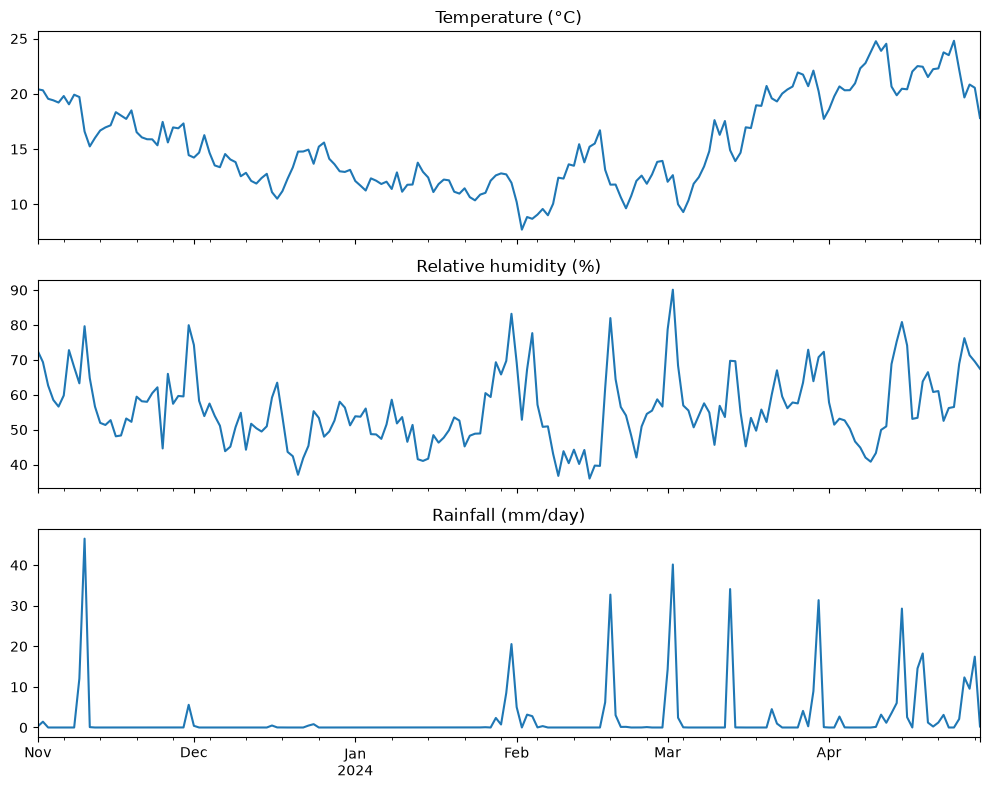

In [3]:
print(weather.describe())

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
weather["temp_c"].plot(ax=axes[0], title="Temperature (°C)")
weather["humidity_pct"].plot(ax=axes[1], title="Relative humidity (%)")
weather["rain_mm"].plot(ax=axes[2], title="Rainfall (mm/day)")
plt.tight_layout()
plt.show()

In [4]:
seasons = {
    "2021-22": ("20211101", "20220430"),
    "2022-23": ("20221101", "20230430"),
    "2023-24": ("20231101", "20240430"),
    "2024-25": ("20241101", "20250430"),
    "2025-26": ("20251101", "20260430"),
}

frames = []
for name, (start, end) in seasons.items():
    df = get_weather(33.68, 73.05, start, end)
    df["season"] = name
    frames.append(df)

all_weather = pd.concat(frames)
print(all_weather.shape)
print(all_weather.isna().sum())
print(all_weather.groupby("season")[["temp_c", "humidity_pct", "rain_mm"]].mean())
all_weather.to_csv(r"D:\AgriVision\data\weather_all_seasons.csv")
print("Saved")

(906, 4)
temp_c          0
humidity_pct    0
rain_mm         0
season          0
dtype: int64
            temp_c  humidity_pct   rain_mm
season                                    
2021-22  15.849613     57.391271  2.679503
2022-23  15.414972     61.601160  2.014917
2023-24  15.537527     56.084341  2.331374
2024-25  16.786354     48.343536  1.042486
2025-26  16.472210     55.046298  2.140552
Saved
